# Two resolutions in, three kinds of output out

A model with one input and one mask is the easy case for a tiler. Sentinel-2 bands come at 10 m and
20 m, and a useful model might want a detailed mask, a coarse map and a single number for each
image. Each of those needs different handling when you stitch a scene, and writing that by hand is
where tiling code usually gets ugly.

Here one ManySeg model has two inputs and three heads, and one ManyPred call handles all of them:

| Head | Shape per patch | What ManyPred does with it |
| --- | --- | --- |
| `water`, full resolution | `(B, 2, H, W)` | Blends a mosaic on the 10 m grid |
| `coarse`, a quarter of the resolution | `(B, 2, H/4, W/4)` | Blends a mosaic on its own 40 m grid |
| `fraction`, one number per image | `(B, 1)` | Keeps one value per patch, which you can map or reduce |

It uses the same chips and flood tile as [the flood notebook](02_flood_scene.ipynb), so it
downloads nothing new after that one, or about 0.9 GB if you start here. It takes a couple of minutes
on a GPU, plus the downloads.

You need `pip install "manypred[geo]" manyseg matplotlib`.

In [1]:
import json
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen, urlretrieve

import manyseg
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import torch
import torch.nn.functional as F
from manyseg import create_model
from manyseg.losses import multiclass_dice
from torch.utils.data import DataLoader, Dataset

from manypred import TilePredictions, predict_array, predict_batch, predict_files
from manypred.geo import stack_rasters

DATA = Path(os.environ.get("MANYPRED_DATA", "data"))  # downloads go here
SMOKE = os.environ.get("MANYPRED_NOTEBOOK_SMOKE") == "1"  # the test suite: a few chips, one epoch
N_TRAIN, EPOCHS = (4, 1) if SMOKE else (160, 100)
RESOLUTION, PATCH, OVERLAP = (160, 256, 64) if SMOKE else (10, 1024, 256)
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

## Chips on two grids

Sen1Floods11 resamples every band to 10 m, so we average the 20 m bands back down to their true
resolution. That way training sees what the tiles will give it. The three targets all come from
the hand labels. A coarse pixel counts as water if most of its labelled area is, and the fraction
is the share of labelled pixels that are water.

In [2]:
BUCKET = "https://storage.googleapis.com/sen1floods11/v1.1"
FOLDER = f"{BUCKET}/data/flood_events/HandLabeled"
ALL_BANDS = (
    "B01",
    "B02",
    "B03",
    "B04",
    "B05",
    "B06",
    "B07",
    "B08",
    "B8A",
    "B09",
    "B10",
    "B11",
    "B12",
)
BANDS_10M, BANDS_20M = ("B03", "B04"), ("B8A", "B11", "B12")


def split_names(split):
    url = f"{BUCKET}/splits/flood_handlabeled/flood_{split}_data.csv"
    lines = urlopen(url).read().decode().split()
    return sorted(line.split("_S1Hand")[0] for line in lines)


def read_tif(name, kind):
    path = DATA / "sen1floods11" / kind / f"{name}_{kind}.tif"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{FOLDER}/{kind}/{name}_{kind}.tif", path)
    with rasterio.open(path) as src:
        return src.read().astype(np.float32)


def load_chips(names):
    with ThreadPoolExecutor(8) as pool:
        images = np.nan_to_num(np.stack(list(pool.map(lambda n: read_tif(n, "S2Hand"), names))))
        labels = np.stack(list(pool.map(lambda n: read_tif(n, "LabelHand")[0], names)))
    fine = images[:, [ALL_BANDS.index(b) for b in BANDS_10M]]
    coarse = images[:, [ALL_BANDS.index(b) for b in BANDS_20M]]
    coarse = F.avg_pool2d(torch.from_numpy(coarse), 2).numpy()
    return fine, coarse, np.where(labels < 0, 255, labels).astype(np.int64)


names = sorted(rng.permutation(split_names("train"))[:N_TRAIN].tolist())
fine, coarse, labels = load_chips(names)
print(f"10 m {fine.shape}, 20 m {coarse.shape}, labels {labels.shape}")


def stats(x):
    return x.mean((0, 2, 3), keepdims=True), x.std((0, 2, 3), keepdims=True) + 1e-6


(fine_mean, fine_std), (coarse_mean, coarse_std) = stats(fine), stats(coarse)

10 m (160, 2, 512, 512), 20 m (160, 3, 256, 256), labels (160, 512, 512)


## One model, three heads

The first input sets the grid. `same_extent` says the second covers the same ground in fewer
pixels. The heads declare their own scale and scope, and ManyPred reads those later from the
model's `tiling_spec()`.

In [3]:
model = create_model(
    pretrained=False,
    inputs={
        "s10": {"in_channels": len(BANDS_10M), "backbone": "resnet18"},
        "s20": {"in_channels": len(BANDS_20M), "backbone": "resnet18", "alignment": "same_extent"},
    },
    fusion={"type": "intermediate", "op": "gated"},
    heads={
        "water": {"type": "segmentation", "out_channels": 2},
        "coarse": {"type": "segmentation", "out_channels": 2, "scale": 0.25},
        "fraction": {"type": "regression", "out_channels": 1, "scope": "image"},
    },
).to(device)


class Crops(Dataset):
    def __init__(self, size=256):
        self.fine = (fine - fine_mean) / fine_std
        self.coarse = (coarse - coarse_mean) / coarse_std
        self.size = size

    def __len__(self):
        return len(self.fine)

    def __getitem__(self, i):
        top, left = 2 * np.random.randint(0, (self.fine.shape[-1] - self.size) // 2 + 1, 2)
        s = self.size
        y = labels[i][top : top + s, left : left + s]
        a = self.fine[i][..., top : top + s, left : left + s]
        b = self.coarse[i][..., top // 2 : (top + s) // 2, left // 2 : (left + s) // 2]
        if np.random.rand() < 0.5:
            a, b, y = a[..., ::-1], b[..., ::-1], y[..., ::-1]
        return (torch.from_numpy(a.copy()), torch.from_numpy(b.copy()), torch.from_numpy(y.copy()))


def coarse_target(y):
    """(B, H, W) labels to a quarter of the size: majority of the labelled pixels, else 255."""
    known = (y != 255).float()[:, None]
    water = (y == 1).float()[:, None]
    known_share = F.avg_pool2d(known, 4)
    share = F.avg_pool2d(water, 4) / known_share.clamp(min=1e-6)
    return torch.where(known_share[:, 0] > 0, (share[:, 0] > 0.5).long(), 255)


def loss_fn(out, y):
    known = (y != 255).float()
    fraction = ((y == 1).float() * known).sum((1, 2)) / known.sum((1, 2)).clamp(min=1)
    return (
        F.cross_entropy(out["water"], y, ignore_index=255)
        + multiclass_dice(out["water"], y, ignore_index=255)
        + F.cross_entropy(out["coarse"], coarse_target(y), ignore_index=255)
        + 5 * F.binary_cross_entropy_with_logits(out["fraction"][:, 0], fraction)
    )


np.random.seed(0)
loader = DataLoader(Crops(), batch_size=2 if SMOKE else 8, shuffle=True, drop_last=not SMOKE)
optimiser = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
schedule = torch.optim.lr_scheduler.OneCycleLR(
    optimiser, max_lr=1e-3, total_steps=EPOCHS * len(loader)
)
start = perf_counter()
model.train()
for _ in range(EPOCHS):
    total = 0.0
    for a, b, y in loader:
        a, b, y = a.to(device), b.to(device), y.to(device)
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            loss = loss_fn(model({"s10": a, "s20": b}), y)
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
        schedule.step()
        total += loss.item()
print(f"{EPOCHS} epochs in {perf_counter() - start:.0f} s, final loss {total / len(loader):.3f}")

Path("runs").mkdir(exist_ok=True)
path = manyseg.save(
    model,
    "runs/two_grids.safetensors",
    normalize={
        "s10": [
            {"type": "zscore", "mean": fine_mean.ravel().tolist(), "std": fine_std.ravel().tolist()}
        ],
        "s20": [
            {
                "type": "zscore",
                "mean": coarse_mean.ravel().tolist(),
                "std": coarse_std.ravel().tolist(),
            }
        ],
    },
    activations={"water": "softmax", "coarse": "softmax", "fraction": "sigmoid"},
)
del model
model = manyseg.load(path)
print(json.dumps(model.tiling_spec()["outputs"], indent=1))

100 epochs in 63 s, final loss 1.164


{
 "water": {
  "scope": "pixel",
  "kind": "segmentation",
  "scale": 1.0,
  "activation": "softmax"
 },
 "coarse": {
  "scope": "pixel",
  "kind": "segmentation",
  "scale": 0.25,
  "activation": "softmax"
 },
 "fraction": {
  "scope": "image",
  "kind": "regression",
  "activation": "sigmoid"
 }
}


## One call for the whole tile

The input is a dict of arrays. ManyPred works out from the shapes that `s20` is half the size of
`s10`, and reads each patch's window from both. `patch_size` and `overlap` must divide by 4 here,
so that the coarse head's patches land on whole pixels.

`output` is set per head. `fraction` is a value for each patch, so a blanket `"argmax"` wouldn't
mean anything for it. ManyPred warns if you ask for that, and asking per head removes the warning.

In [4]:
BUCKET_S2 = "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/51/K/YV/2023/1"
SCENE = "S2B_51KYV_20230112_0_L2A"  # the Fitzroy River in flood, 12 Jan 2023


def band_path(band):
    url = f"{BUCKET_S2}/{SCENE}/{band}.tif"
    if SMOKE:  # read the file's overviews over the network instead of downloading it
        return url
    path = DATA / "s2" / SCENE / f"{band}.tif"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def load_inputs(item):
    s10, profile = stack_rasters([band_path(b) for b in BANDS_10M], resolution=RESOLUTION)
    s20, _ = stack_rasters([band_path(b) for b in BANDS_20M], resolution=RESOLUTION * 2)
    return {"s10": s10, "s20": s20}, profile


inputs, profile = load_inputs(SCENE)
print({name: array.shape for name, array in inputs.items()})
settings = {
    "patch_size": PATCH,
    "overlap": OVERLAP,
    "batch_size": 4,
    "nodata": 0,
    "progress": False,
    "output": {"water": "argmax", "coarse": "probs", "fraction": "probs"},
}
start = perf_counter()
result = predict_array(model, inputs, **settings)
print(f"{perf_counter() - start:.1f} s")
for name, value in result.items():
    print(f"{name:9}", type(value).__name__, getattr(value, "values", value).shape)

{'s10': (2, 10980, 10980), 's20': (3, 5490, 5490)}


2.9 s
water     ndarray (1, 10980, 10980)
coarse    ndarray (2, 2745, 2745)
fraction  TilePredictions (169, 1)


## Three outputs, one river

`TilePredictions` keeps the image-level head as what it is, one vector per patch. `to_map` paints
those back onto the scene, and `reduce` averages that map over the valid pixels. Summing wouldn't
work, because overlapping patches would count twice.

In [5]:
fractions = result["fraction"]
assert isinstance(fractions, TilePredictions)
stride = PATCH // 4
fraction_map = fractions.to_map(stride)
print(f"{len(fractions.values)} patches; fraction map {fraction_map.shape}")

water, coarse_probs = result["water"][0], result["coarse"][1]
valid = ~(inputs["s10"] == 0).all(0)
print("water share of the tile, from each head:")
print(f"  10 m mask        {(water[valid] == 1).mean():.2%}")
print(f"  40 m probability {np.nanmean(coarse_probs):.2%}")
print(f"  patch values     {float(fractions.reduce('mean')[0]):.2%}")

169 patches; fraction map (1, 43, 43)
water share of the tile, from each head:
  10 m mask        0.54%


  40 m probability 0.66%


  patch values     1.68%


The three heads don't agree on the number, and that's worth knowing before you trust one. The two
pixel heads are close. The patch values read about four times higher than the 10 m mask. The
plot further down shows why: the fraction head squeezes its answers toward the middle, reading low
on very wet chips and high on nearly dry ones, and this tile is nearly dry. ManyPred stitched all
three correctly, but it can't fix a model's calibration.

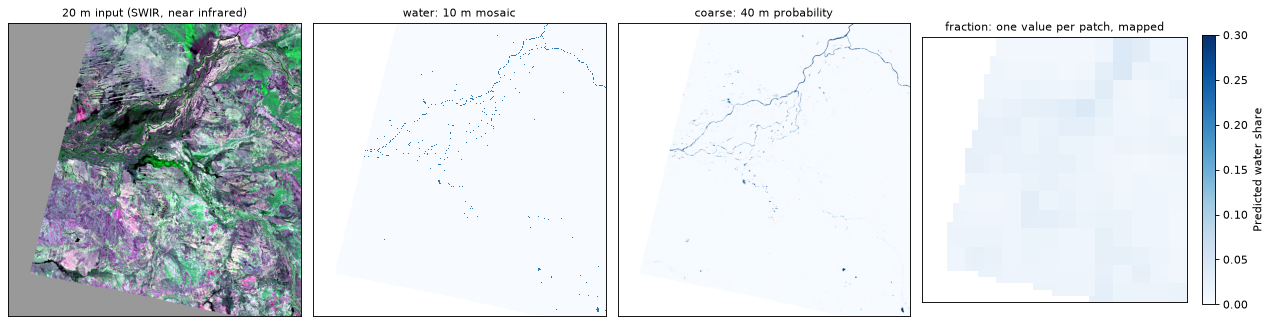

In [6]:
def composite(array):
    rgb = array.transpose(1, 2, 0).astype(np.float32)
    known = (rgb > 0).any(-1)
    if not known.any():
        return np.full(rgb.shape, 0.6)
    low, high = np.percentile(rgb[known], (2, 98), axis=0)
    out = np.clip((rgb - low) / np.maximum(high - low, 1), 0, 1)
    out[~known] = 0.6
    return out


step = max(1, water.shape[0] // 700)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
axes[0].imshow(composite(inputs["s20"][[2, 0, 1], :: step // 2 or 1, :: step // 2 or 1]))
axes[0].set_title("20 m input (SWIR, near infrared)")
axes[1].imshow(
    np.where(valid, water == 1, np.nan)[::step, ::step],
    cmap="Blues",
    vmin=0,
    vmax=1.4,
    interpolation="nearest",
)
axes[1].set_title("water: 10 m mosaic")
axes[2].imshow(
    coarse_probs[:: max(1, step // 4), :: max(1, step // 4)], cmap="Blues", vmin=0, vmax=1
)
axes[2].set_title("coarse: 40 m probability")
image = axes[3].imshow(np.squeeze(fraction_map), cmap="Blues", vmin=0, vmax=0.3)
axes[3].set_title("fraction: one value per patch, mapped")
fig.colorbar(image, ax=axes[3], fraction=0.046, label="Predicted water share")
for ax in axes:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

Up close, the two pixel heads over the same ground. The 40 m head has a sixteenth of the pixels and
blurs the narrow channels, as you'd expect. It also gives a probability instead of a hard class,
which is why it shows the faint side channels. Which one you want depends on the question.

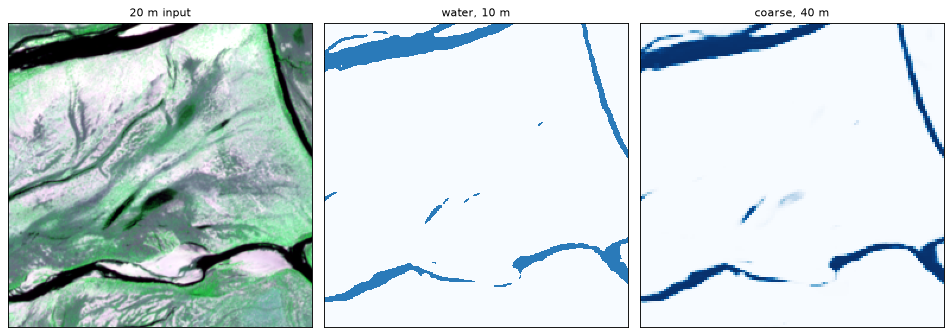

In [7]:
size = PATCH // 2
counts = {
    (r, c): (water[r : r + size, c : c + size] == 1).sum()
    for r in range(0, water.shape[0] - size + 1, size)
    for c in range(0, water.shape[1] - size + 1, size)
    if valid[r : r + size, c : c + size].all()
} or {(0, 0): 0}
top, left = max(counts, key=counts.get)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
axes[0].imshow(
    composite(
        inputs["s20"][[2, 0, 1], top // 2 : (top + size) // 2, left // 2 : (left + size) // 2]
    )
)
axes[0].set_title("20 m input")
axes[1].imshow(
    water[top : top + size, left : left + size],
    cmap="Blues",
    vmin=0,
    vmax=1.4,
    interpolation="nearest",
)
axes[1].set_title("water, 10 m")
axes[2].imshow(
    result["coarse"][1][top // 4 : (top + size) // 4, left // 4 : (left + size) // 4],
    cmap="Blues",
    vmin=0,
    vmax=1,
    interpolation="nearest",
)
axes[2].set_title("coarse, 40 m")
for ax in axes:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## Chips: the same model, no tiling

`predict_batch` takes the same dict of inputs. Without patches there's nothing to map, so the image
head comes back as plain `(N, 1)`. These are the Bolivia chips, which the model didn't train on.
The head ranks them sensibly, but the wettest chips hold far more water than it says.

{'water': (15, 1, 512, 512), 'coarse': (15, 2, 128, 128), 'fraction': (15, 1)}


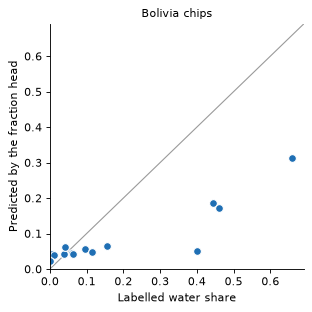

In [8]:
test_fine, test_coarse, test_labels = load_chips(split_names("bolivia")[: 2 if SMOKE else None])
chips = predict_batch(
    model,
    {"s10": test_fine, "s20": test_coarse},
    batch_size=4,
    nodata=0,
    progress=False,
    output={"water": "argmax", "coarse": "probs", "fraction": "probs"},
)
print({name: value.shape for name, value in chips.items()})
truth = np.array([(y[y != 255] == 1).mean() for y in test_labels])

fig, ax = plt.subplots(figsize=(4, 4))
limit = max(truth.max(), chips["fraction"].max()) * 1.05
ax.plot([0, limit], [0, limit], color="#9a9a9a", lw=1)
ax.plot(truth, chips["fraction"][:, 0], "o", color="#1f6fb4", ms=7, mec="white")
ax.set(
    xlabel="Labelled water share",
    ylabel="Predicted by the fraction head",
    title="Bolivia chips",
    xlim=(0, limit),
    ylim=(0, limit),
)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

## Files: one GeoTIFF per head

`predict_files` writes each pixel head as its own GeoTIFF and puts image-level values in a JSON
manifest. The coarse file gets the right pixel size without being asked, so it lines up with the
others in QGIS.

In [9]:
[written] = predict_files(
    model, [SCENE], load_func=load_inputs, output_dir=DATA / "two_grids", overwrite=True, **settings
)
print(written.name)
for path in sorted((DATA / "two_grids").glob(f"{SCENE}*.tif")):
    with rasterio.open(path) as src:
        print(f"{path.name}: {src.shape}, {abs(src.transform.a):.0f} m pixels")
manifest = json.loads((DATA / "two_grids" / f"{SCENE}_pred.json").read_text())
print("manifest keys:", list(manifest))

S2B_51KYV_20230112_0_L2A_pred.json
S2B_51KYV_20230112_0_L2A_pred_coarse.tif: (2745, 2745), 40 m pixels
S2B_51KYV_20230112_0_L2A_pred_water.tif: (10980, 10980), 10 m pixels
manifest keys: ['files', 'values']


## Where to go next

* Turn a raster into polygons one block at a time, in [the next notebook](04_blocks_to_polygons.ipynb).
* Time series and metadata vectors work as inputs too. See "Several inputs" in the
  [README](https://github.com/DPIRD-DMA/ManyPred#several-inputs).